# Logistic Regression and Evaluation — Concepts

Read the idea, the formula and the small example in that order. The demonstration code is provided.

## Libraries and settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay

## 1. From a score to a probability

Logistic regression uses a linear score and an S-shaped **sigmoid**:
$$z=\beta_0+\beta_1x,\qquad p=P(y=1\mid x)=\frac1{1+e^{-z}}.$$
$z$ is the score; $p$ is between 0 and 1. For $\beta_0=-5$, $\beta_1=1$, $x=6$: $z=1$ and $p\approx0.73$. A positive coefficient means larger input values give higher predicted probability, holding other inputs fixed.

Several inputs are combined in the score in the same way as in multiple linear regression. Fitting uses maximum likelihood, equivalently minimising **log-loss**:
$$L(y,p)=-[y\log(p)+(1-y)\log(1-p)].$$
For a true positive ($y=1$), predicting $p=0.9$ is better than $p=0.1$. A numerical optimiser finds the coefficients; we use `fit`.

Probability: 0.7310585786300049


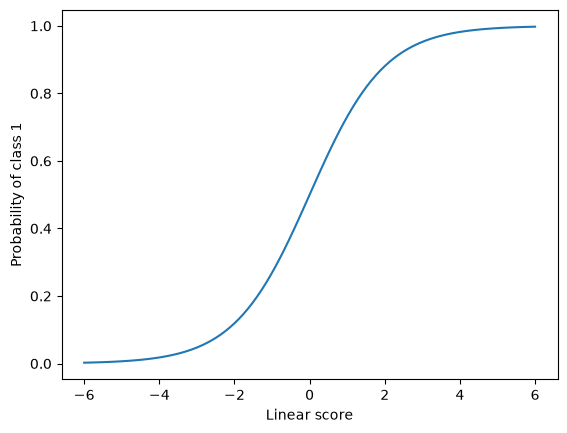

In [2]:
score = 1
print('Probability:', 1 / (1 + np.exp(-score)))
x = np.linspace(-6, 6, 100)
plt.plot(x, 1 / (1 + np.exp(-x)))
plt.xlabel('Linear score')
plt.ylabel('Probability of class 1')
plt.show()

## 2. Confusion matrix and metrics

Rows are actual classes; columns predicted classes:

| | Predicted 0 | Predicted 1 |
|---|---|---|
| Actual 0 | TN: correct negative | FP: false alarm |
| Actual 1 | FN: missed positive | TP: correct positive |

$$\mathrm{accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad
\mathrm{precision}=\frac{TP}{TP+FP},\quad
\mathrm{recall}=\frac{TP}{TP+FN}.$$
$$\mathrm{FPR}=\frac{FP}{FP+TN},\qquad F1=\frac{2\,\mathrm{precision}\,\mathrm{recall}}{\mathrm{precision}+\mathrm{recall}}.$$
Accuracy: how many are correct overall? Precision: how many predicted positives are real positives? Recall: how many actual positives did we find? FPR: how many actual negatives were falsely flagged? F1 balances precision and recall.

With TN=75, FP=22, FN=24, TP=50, precision is 50/72 and recall is 50/74. If positives are rare, predicting “always negative” can have high accuracy but zero recall.

In [3]:
TN, FP, FN, TP = 75, 22, 24, 50
print('Accuracy:', (TP + TN) / (TP + TN + FP + FN))
print('Precision:', TP / (TP + FP))
print('Recall:', TP / (TP + FN))

Accuracy: 0.7309941520467836
Precision: 0.6944444444444444
Recall: 0.6756756756756757


## 3. A threshold turns probability into a class

Predict positive if the estimated probability reaches a threshold $\tau$:
$$\hat y=1\quad\mathrm{if}\quad p\geq\tau.$$
At $p=0.4$, a threshold of 0.5 predicts 0; a threshold of 0.3 predicts 1. Lowering the threshold finds more positives but can create more false alarms. Recall and FPR cannot decrease when the threshold is lowered. Precision may rise when raising the threshold, but this is not guaranteed.

Choose thresholds using validation data and the cost of errors, for example:
$$\mathrm{total\ cost}=c_{FN}\,FN+c_{FP}\,FP.$$
$c_{FN}$ and $c_{FP}$ are the costs of a missed positive and a false alarm. We compare two fixed thresholds for illustration; we do not optimise them on the test set.

## 4. ROC and AUC

A **ROC curve** plots recall (true positive rate) against FPR for many thresholds. Each threshold gives one point. The diagonal corresponds to random ranking in expectation.

**AUC** is the area under the curve. AUC = 0.5 means random ranking; AUC = 1 means perfect ranking. It is the chance that a randomly chosen positive receives a higher score than a randomly chosen negative (ties count half). Use probabilities or continuous scores, not just 0/1 predictions, for ROC/AUC.

## 5. What information is available?

Our avalanche example predicts a fatal outcome **among recorded accidents**, using the number of fully buried people. That information is available after an accident, not before a trip.

The model does not predict whether an avalanche will happen. To predict before an accident, inputs must be available at that earlier time. This distinction prevents an unrealistic prediction task. Missing data and changes in reporting also affect interpretation.

### Jupyter notebook — footer info

Include this information when submitting your notebook.

In [4]:
import platform
from datetime import datetime
print(platform.platform())
print("Python:", platform.python_version())
print("Date:", datetime.now().isoformat(timespec="seconds"))

Linux-6.8.0-1064-azure-x86_64-with-glibc2.36
Python: 3.12.11
Date: 2026-10-26T06:57:01
